## **Importacion de librerias**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

---

## **Carga de datos**


In [2]:
df = pd.read_parquet("./data/tabla_total.parquet").dropna()

In [3]:
df_debito = df[df["producto"].str.contains("DEBITO", case=False, na=False)].copy()

---

## **Analisis exploratorio: Variables RFM**


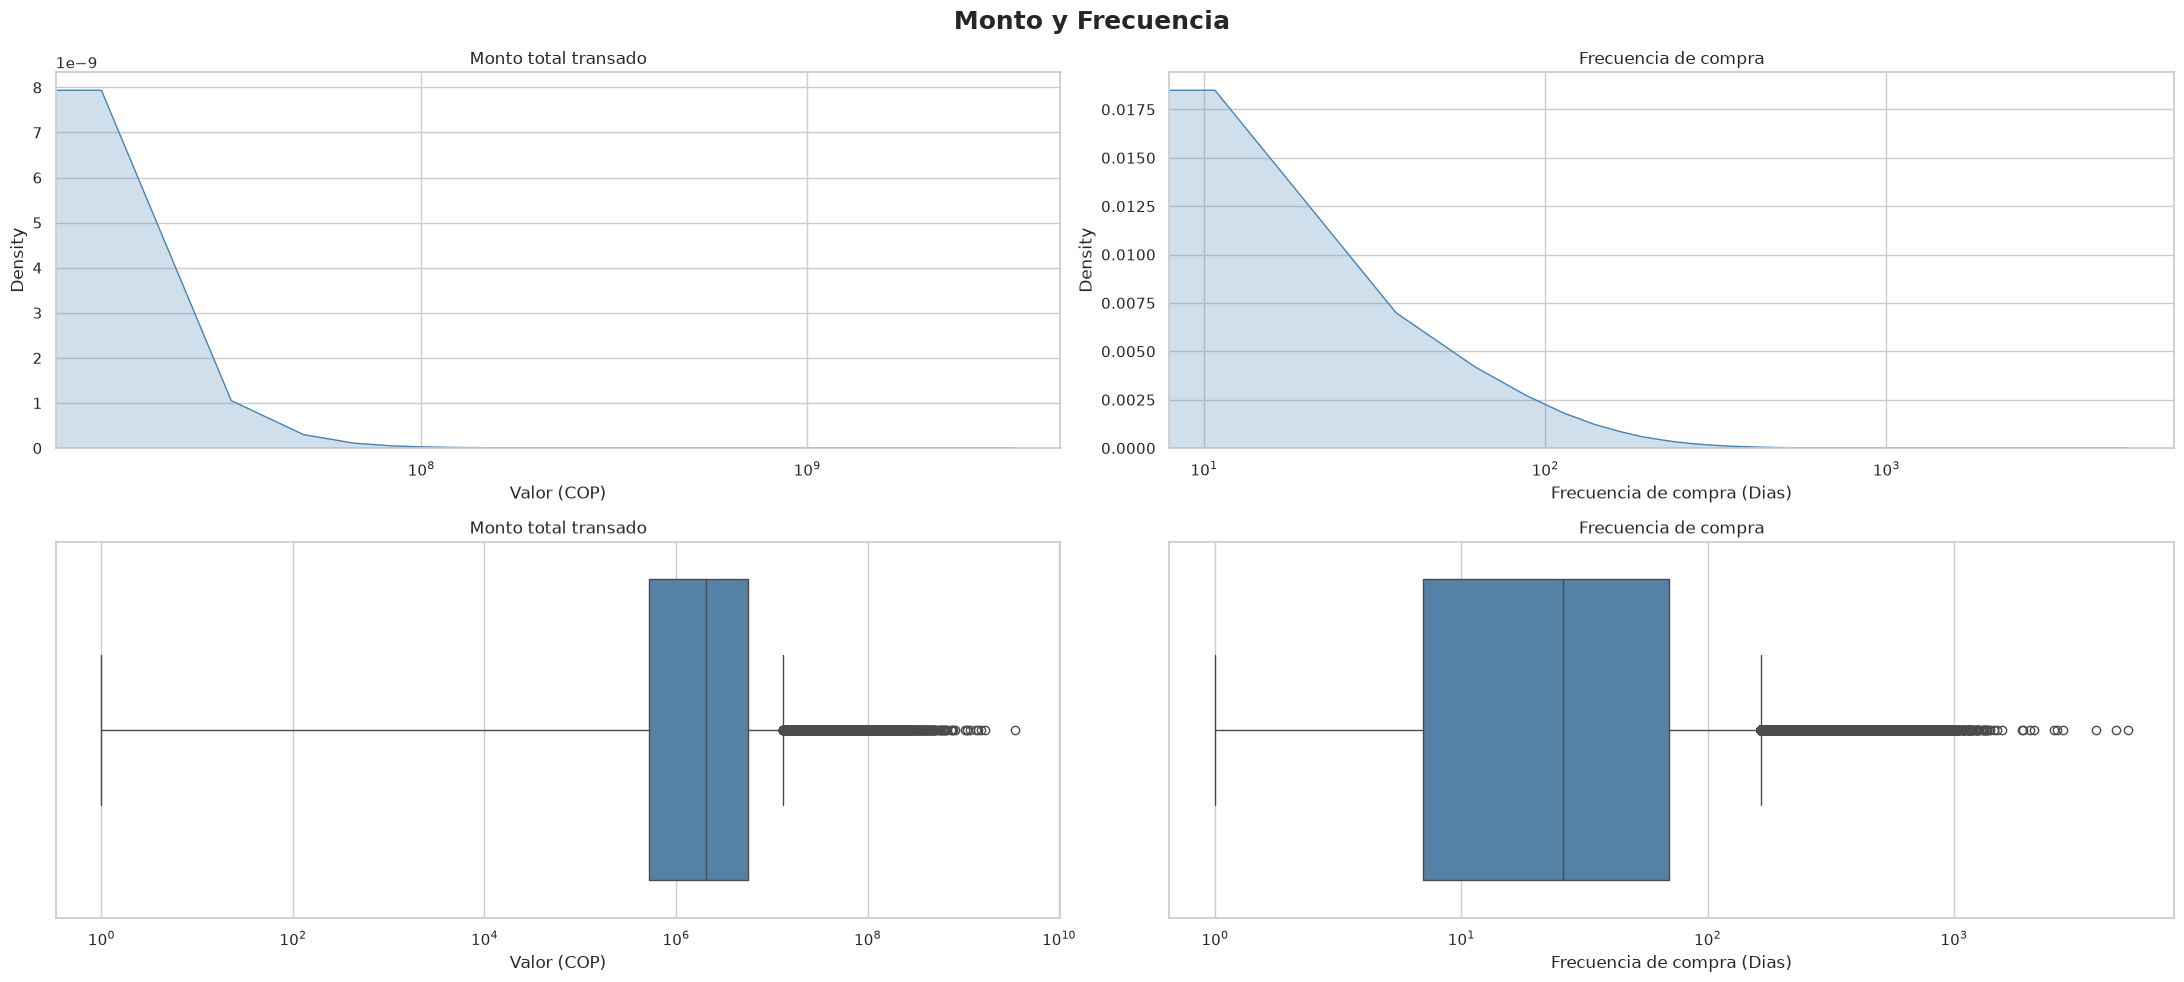

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(22, 10))

fig.suptitle(
    "Monto y Frecuencia",
    fontsize=18,
    fontweight="bold",
)

## MONTO TOTAL
# Gráfico de densidad
sns.kdeplot(
    data=df_debito,
    x="valor_total",
    fill=True,
    color="steelblue",
    ax=axes[0, 0],
)

axes[0, 0].set_title(f"Monto total transado")
axes[0, 0].set_xlabel("Valor (COP)")
axes[0, 0].set_xscale("log")

# Boxplot
sns.boxplot(data=df_debito, x="valor_total", color="steelblue", ax=axes[1, 0])

axes[1, 0].set_title(f"Monto total transado")
axes[1, 0].set_xlabel("Valor (COP)")
axes[1, 0].set_xscale("log")

## FRECUENCIA
# Gráfico de densidad
sns.kdeplot(
    data=df_debito,
    x="frecuencia",
    fill=True,
    color="steelblue",
    ax=axes[0, 1],
)

axes[0, 1].set_title(f"Frecuencia de compra")
axes[0, 1].set_xlabel("Frecuencia de compra (Dias)")
axes[0, 1].set_xscale("log")

# Boxplot
sns.boxplot(data=df_debito, x="frecuencia", color="steelblue", ax=axes[1, 1])

axes[1, 1].set_title(f"Frecuencia de compra")
axes[1, 1].set_xlabel("Frecuencia de compra (Dias)")
axes[1, 1].set_xscale("log")

plt.tight_layout()
plt.show()

Las graficas anteriores demuestran que hay un sesgo muy grande en los datos del valor transado de todos los clientes. Esto se debe a que el dataset contiene clientes de Bancolombia de todos los segmentos, y de acuerdo a esto habran diferentes capacidades economicas en el consumo de ambos productos. Adicionalmente, los datos no discriminan persona natural o juridica, lo cual hace que la diferencia aumente mas, pues un cliente catalogado como persona juridica posiblemente corresponda con alguna empresa, las cuales suelen hacer gastos aun mayores. Del mismo modo, para la frecuencia se observa un comportamiento similar.


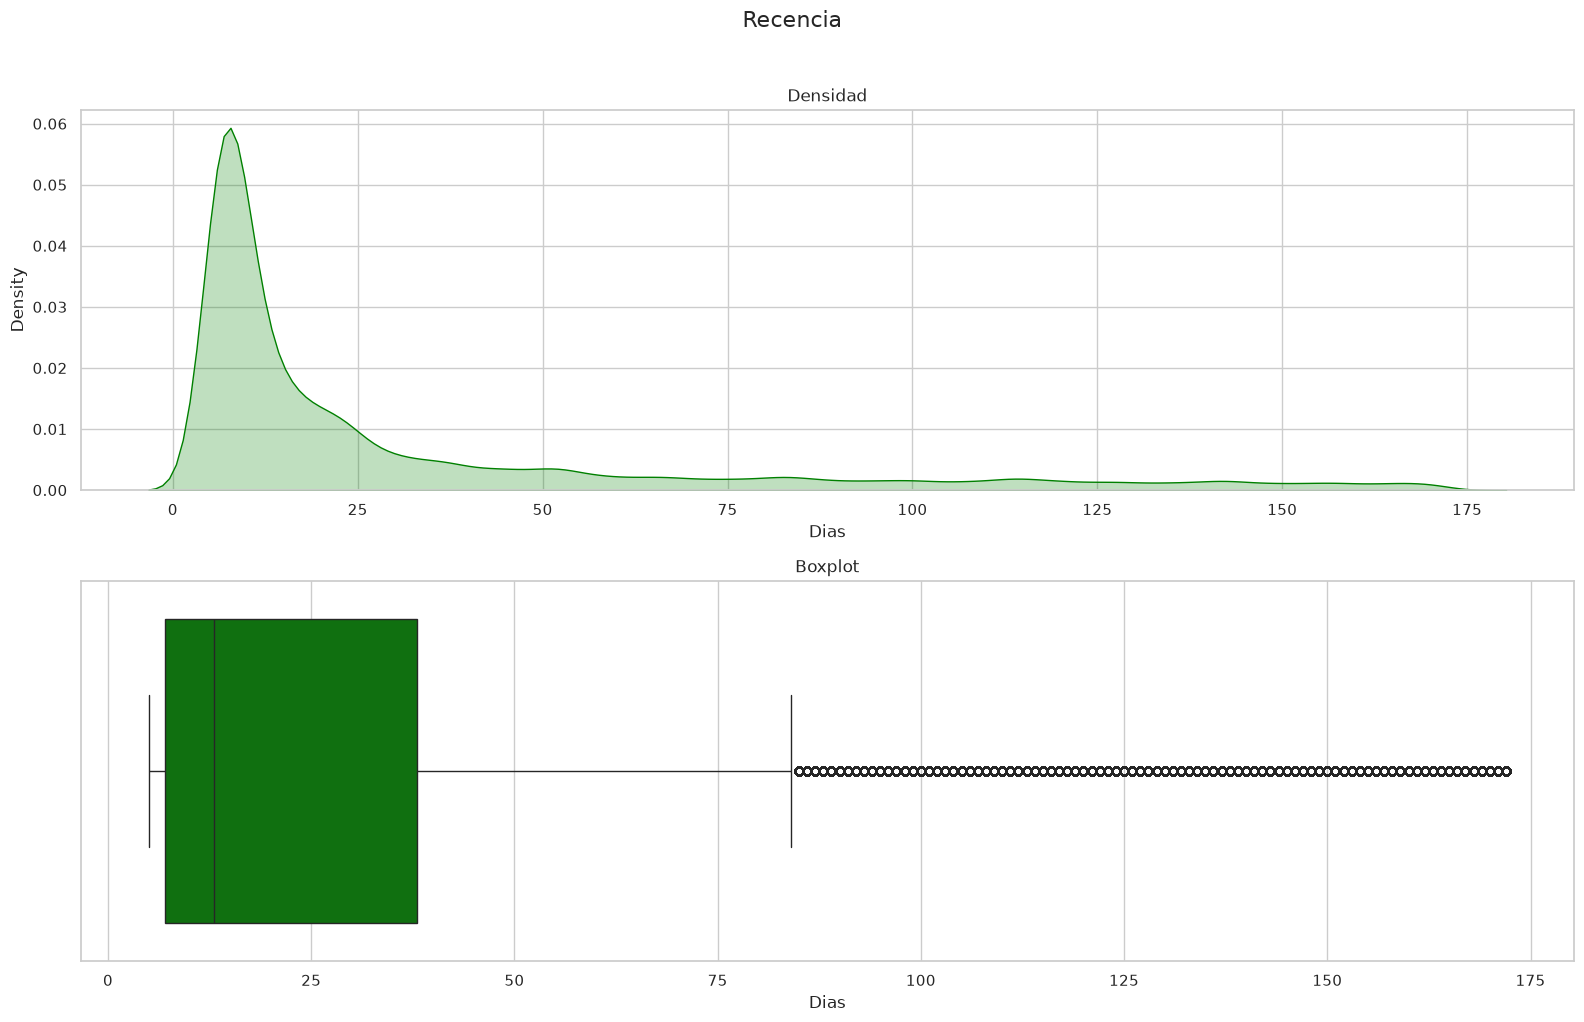

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Recencia", fontsize=16, y=1.02)

# 1. Density Plots
sns.kdeplot(
    data=df_debito,
    x="recency_dias",
    fill=True,
    color="green",
    ax=axes[0],
)
axes[0].set_title("Densidad")
axes[0].set_xlabel("Dias")

axes[1].set_title("Boxplot")
axes[1].set_xlabel("Dias")

# # 2. Boxplots
sns.boxplot(data=df_debito, x="recency_dias", color="green", ax=axes[1])
axes[1].set_title("Boxplot")


plt.tight_layout()
plt.show()

Para la variable de recencia se observa un comportamiento sesgado, aunque no de la misma magnitud que para la frecuencia de compra y monto total transado. Esto tiene sentido ya que la recencia es un valor que esta registrido en la ventana temporal del analisis, la cual corresponde a 6 meses. Esto significa que por mas sesgado que este un valor de recencia, este no superara aproximadamente los 180 dias.

Estas graficas son la razon de la cual es necesario aplicar un escalamiento en los datos. Se observa que las tres variables poseen distribuciones sesgadas, y adicionalmente se miden en unidades diferentes, por lo cual es escalamiento se hace necesario antes de proceder a aplicar el algoritmo de clustering.


---

## **Escalamiento de datos**


In [6]:
num_cols = ["recency_dias", "frecuencia", "valor_total"]
cat_cols = ["desc_segmento", "desc_genero"]

pt = PowerTransformer(method="yeo-johnson", standardize=True)

In [7]:
df_debito_num_scaled = pd.DataFrame(
    pt.fit_transform(df_debito[num_cols]), columns=num_cols, index=df_debito.index
)

df_debito_procesado = pd.concat([df_debito_num_scaled, df_debito[cat_cols]], axis=1)

display(df_debito_procesado.head())

,recency_dias,frecuencia,valor_total,desc_segmento,desc_genero
5080290,0.489137,-0.374214,-0.738656,PERSONAL,FEMENINO
2077692,-0.809934,0.588348,0.344044,PERSONAL,FEMENINO
5017407,1.368864,-0.374214,-0.551993,PLUS,MASCULINO
4877830,-1.268048,1.015343,0.910170,INDEPENDIENTES,MASCULINO
4752156,-0.139982,0.074557,0.057239,PERSONAL,FEMENINO


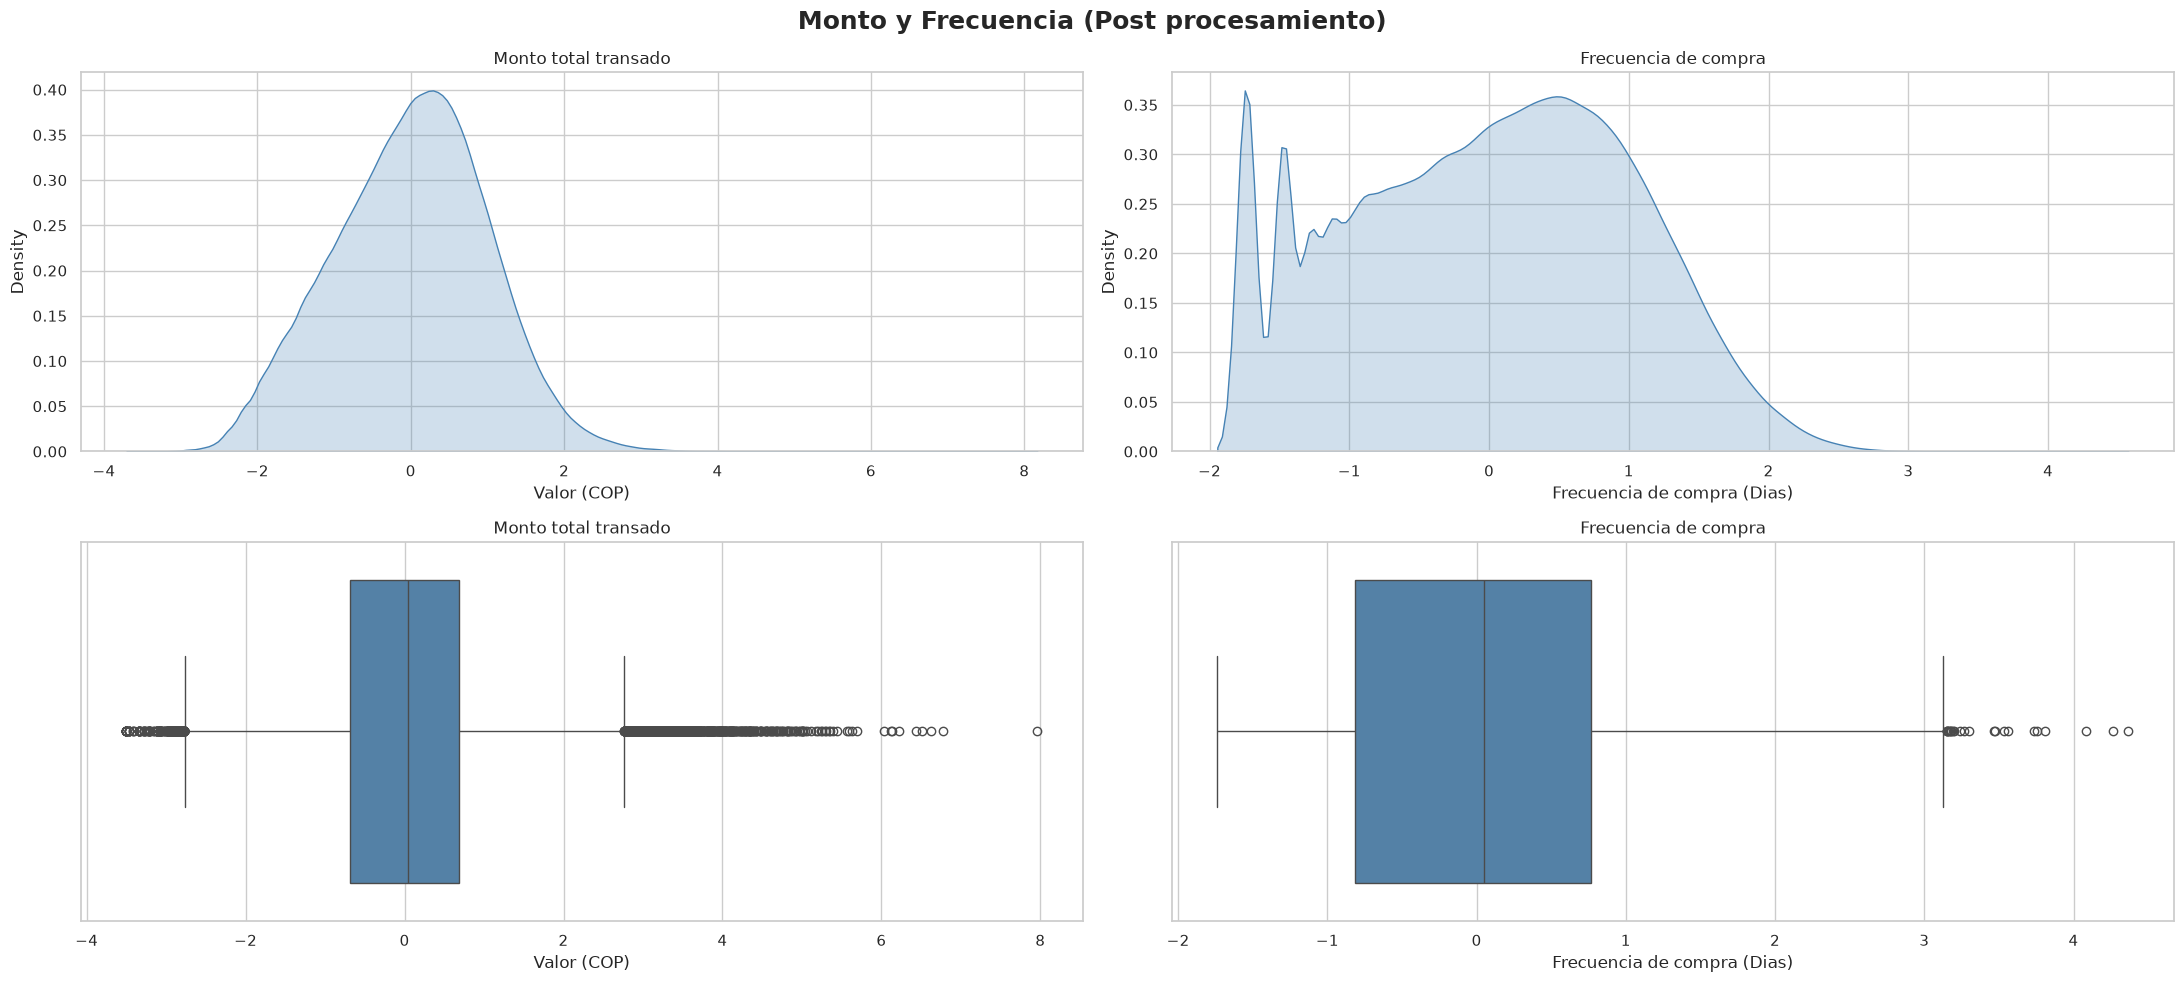

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(22, 10))

fig.suptitle(
    "Monto y Frecuencia (Post procesamiento)",
    fontsize=18,
    fontweight="bold",
)

## MONTO TOTAL
# Gráfico de densidad
sns.kdeplot(
    data=df_debito_procesado,
    x="valor_total",
    fill=True,
    color="steelblue",
    ax=axes[0, 0],
)

axes[0, 0].set_title(f"Monto total transado")
axes[0, 0].set_xlabel("Valor (COP)")

# Boxplot
sns.boxplot(data=df_debito_procesado, x="valor_total", color="steelblue", ax=axes[1, 0])

axes[1, 0].set_title(f"Monto total transado")
axes[1, 0].set_xlabel("Valor (COP)")

## FRECUENCIA
# Gráfico de densidad
sns.kdeplot(
    data=df_debito_procesado,
    x="frecuencia",
    fill=True,
    color="steelblue",
    ax=axes[0, 1],
)

axes[0, 1].set_title(f"Frecuencia de compra")
axes[0, 1].set_xlabel("Frecuencia de compra (Dias)")

# Boxplot
sns.boxplot(data=df_debito_procesado, x="frecuencia", color="steelblue", ax=axes[1, 1])

axes[1, 1].set_title(f"Frecuencia de compra")
axes[1, 1].set_xlabel("Frecuencia de compra (Dias)")

plt.tight_layout()
plt.show()

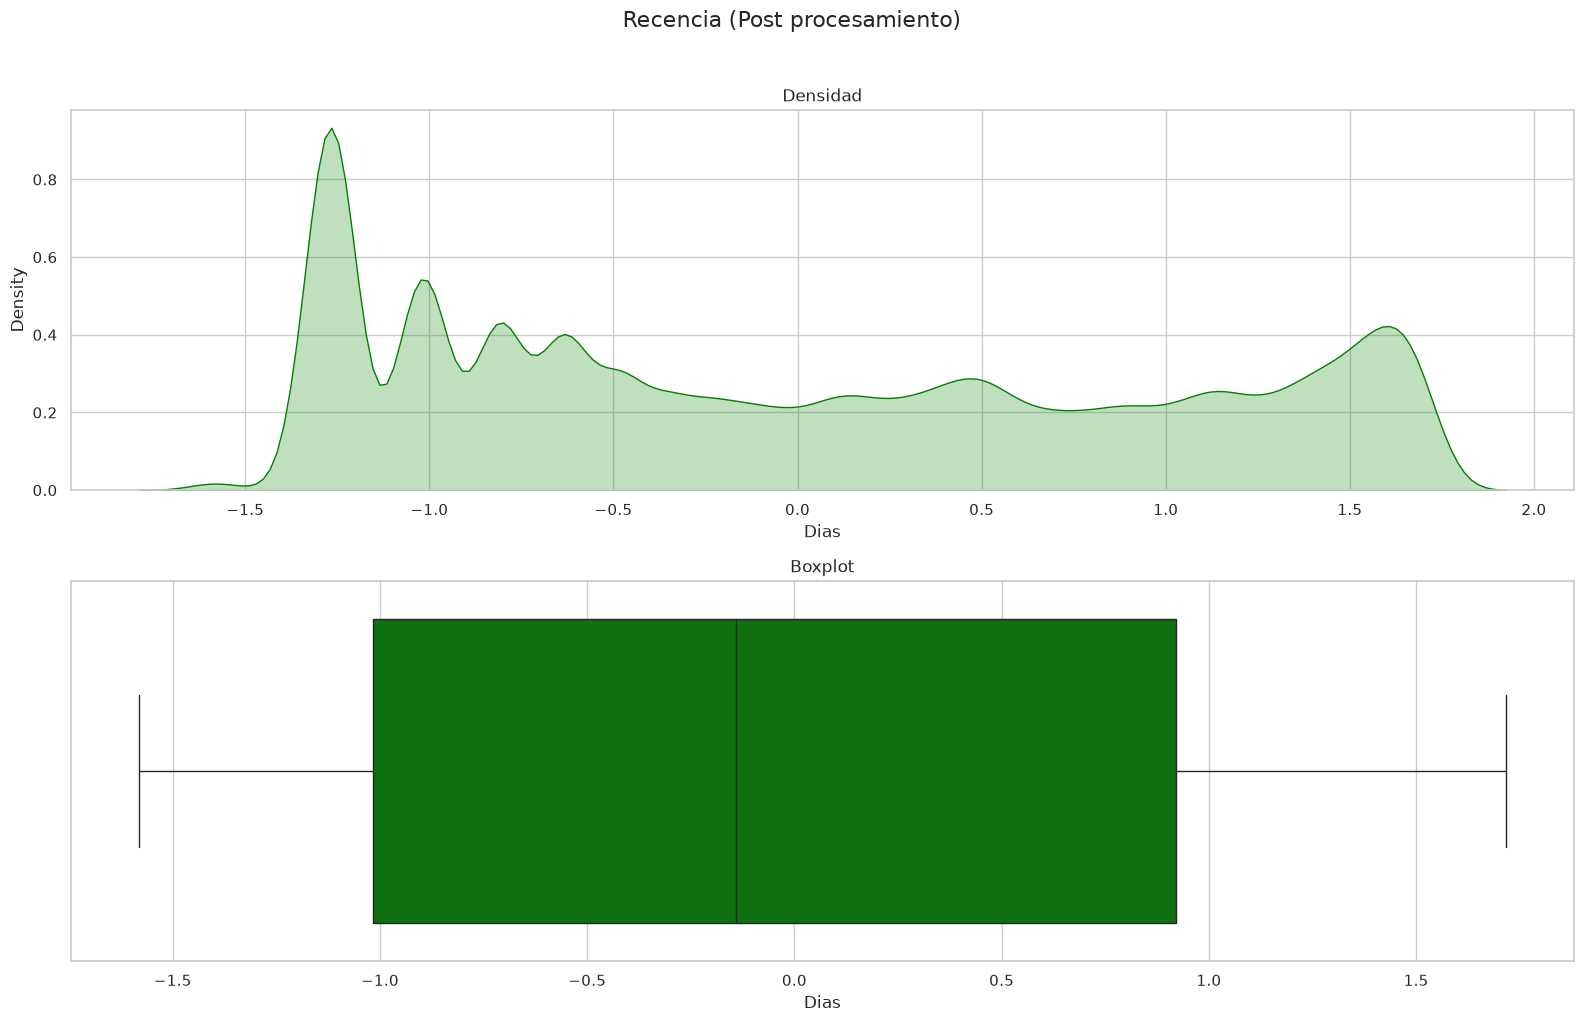

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Recencia (Post procesamiento)", fontsize=16, y=1.02)

# 1. Density Plots
sns.kdeplot(
    data=df_debito_procesado,
    x="recency_dias",
    fill=True,
    color="green",
    ax=axes[0],
)
axes[0].set_title("Densidad")
axes[0].set_xlabel("Dias")

axes[1].set_title("Boxplot")
axes[1].set_xlabel("Dias")

# # 2. Boxplots
sns.boxplot(data=df_debito_procesado, x="recency_dias", color="green", ax=axes[1])
axes[1].set_title("Boxplot")


plt.tight_layout()
plt.show()

## **K-Means**


In [10]:
# Variables RFM seleccionadas
X_rfm = df_debito_procesado[["recency_dias", "frecuencia", "valor_total"]]

### Optimizacion de Hiperparametros

El unico hiperparametro a optimizar en este caso vendria a ser el numero de clusters. El algoritmo de K-Means nos exige especificar manualmente este numero, por lo cual, antes de ingresarlo al modelo final, podriamos estudiar como se comportan ciertas metricas para diferentes numeros de clusters. Sin embargo, debemos de tener en cuenta que estas metricas son altamente heuristicas, por lo cual no se recomienda siempre tenerlas como fuente de la verdad, sino como una referencia adicional para la seleccion de este numero adecuado, ya que en la vida real debemos de tener en cuenta que esto puede estar directamente ligado a decisiones estrategicas o de negocio para posteriormente volver accionables estos segmentos resultantes.


In [11]:
inertia = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_rfm)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_rfm, kmeans.labels_, sample_size=25_000, random_state=42)
    )

    print(f"k={k}, inertia={kmeans.inertia_}, silhouette_score={silhouette_scores[-1]}")

k=2, inertia=802282.2554515001, silhouette_score=0.476395902694859
k=3, inertia=574192.1923398401, silhouette_score=0.37077943425651494
k=4, inertia=458831.72414449265, silhouette_score=0.3534393368719185
k=5, inertia=384447.31522255024, silhouette_score=0.3327511226744849
k=6, inertia=331874.10462554503, silhouette_score=0.3116011012579039
k=7, inertia=299875.9694085733, silhouette_score=0.300999066520604


La optimizacion de hiperparametros realmente no es un proceso infalible, y en la vida real normalmente los datos no estan completamente separados entre si. En este caso observamos puntajes de silhouette relativamente bajos, pero normales para el contexto de clustering con variables RFM. Tambien esto puede ser debido a que los clusters resultantes realmente no tienen tamanos esfericos, por lo cual otras tecnicas mas avanzadas de clustering podrian generar mejores resultados para tamanos mas irregulares.


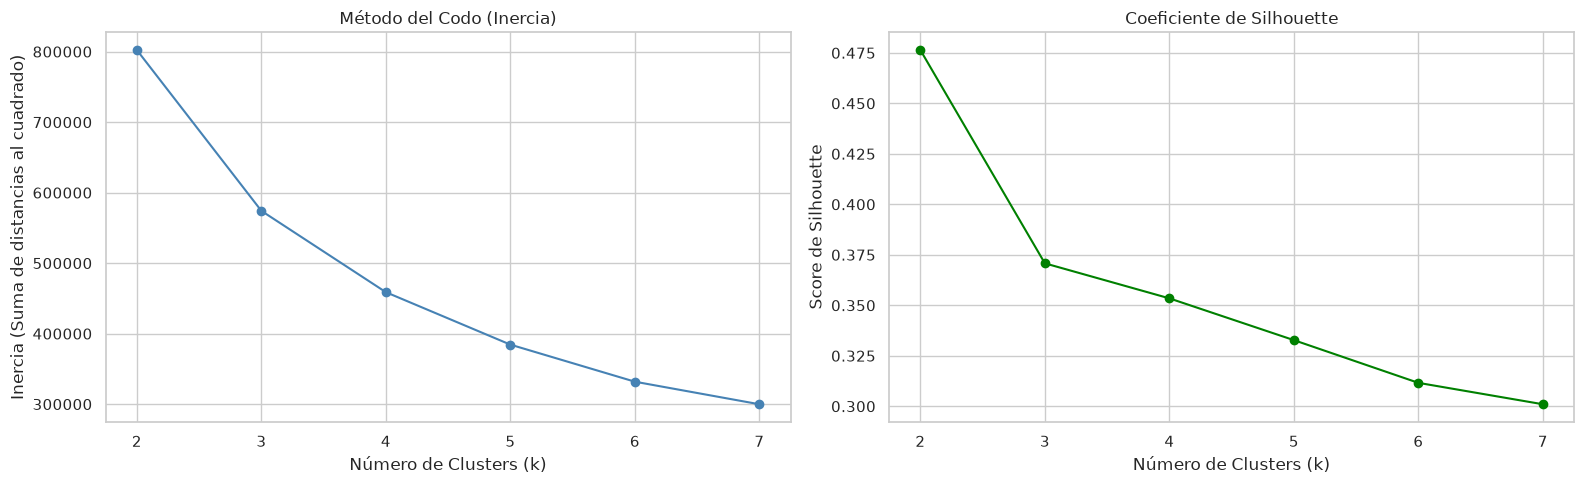

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Metodo del codo
axes[0].plot(K_range, inertia, marker="o", color="steelblue")
axes[0].set_title("Método del Codo (Inercia)")
axes[0].set_xlabel("Número de Clusters (k)")
axes[0].set_ylabel("Inercia (Suma de distancias al cuadrado)")

# Gráfico de Silhouette
axes[1].plot(K_range, silhouette_scores, marker="o", color="green")
axes[1].set_title("Coeficiente de Silhouette")
axes[1].set_xlabel("Número de Clusters (k)")
axes[1].set_ylabel("Score de Silhouette")

plt.tight_layout()
plt.show()

## **Entrenamiento del modelo**


In [13]:
k_optimo = 4

modelo_kmeans = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)

df_debito_procesado["cluster"] = modelo_kmeans.fit_predict(X_rfm)

# Asignar los clusters al dataframe original (sin escalar) para facilitar la interpretacion de negocio
df_debito["cluster"] = df_debito_procesado["cluster"]

display(df_debito[["recency_dias", "frecuencia", "valor_total", "cluster"]].head())

,recency_dias,frecuencia,valor_total,cluster
5080290,23,14,471512,3
2077692,8,55,3321655,0
5017407,77,14,688371,3
4877830,6,97,7667732,1
4752156,13,27,2084608,0


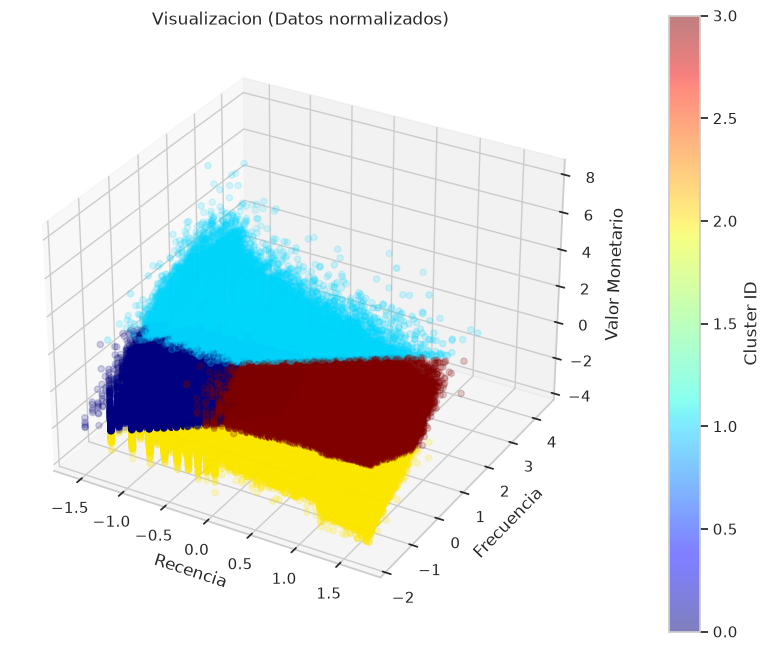

In [14]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

x = df_debito_procesado["recency_dias"]
y = df_debito_procesado["frecuencia"]
z = df_debito_procesado["valor_total"]
clusters = df_debito_procesado["cluster"]

# Create the 3D scatter plot
scatter = ax.scatter(x, y, z, c=clusters, cmap="jet", s=20, alpha=0.5)

ax.set_title("Visualizacion (Datos normalizados)")
ax.set_xlabel("Recencia")
ax.set_ylabel("Frecuencia")
ax.set_zlabel("Valor Monetario")

# Add a color bar mapping to the clusters
plt.colorbar(scatter, label="Cluster ID", pad=0.1)

plt.show()